In [1]:
import os

root = "../data"   # change this to your dataset folder

for folder, subfolders, files in os.walk(root):
    print(folder, "->", len(files), "files")

../data -> 0 files
../data/Val -> 0 files
../data/Val/Glioma -> 0 files
../data/Val/Glioma/labels -> 136 files
../data/Val/Glioma/images -> 136 files
../data/Val/No Tumor -> 0 files
../data/Val/No Tumor/labels -> 100 files
../data/Val/No Tumor/images -> 100 files
../data/Val/Pituitary -> 0 files
../data/Val/Pituitary/labels -> 136 files
../data/Val/Pituitary/images -> 136 files
../data/Val/Meningioma -> 0 files
../data/Val/Meningioma/labels -> 140 files
../data/Val/Meningioma/images -> 140 files
../data/Train -> 0 files
../data/Train/Glioma -> 0 files
../data/Train/Glioma/labels -> 1153 files
../data/Train/Glioma/images -> 1153 files
../data/Train/No Tumor -> 0 files
../data/Train/No Tumor/labels -> 711 files
../data/Train/No Tumor/images -> 711 files
../data/Train/Pituitary -> 0 files
../data/Train/Pituitary/labels -> 1424 files
../data/Train/Pituitary/images -> 1424 files
../data/Train/Meningioma -> 0 files
../data/Train/Meningioma/labels -> 1449 files
../data/Train/Meningioma/images

In [2]:
import os

base = "../data/Train/Glioma"
label_name = sorted(os.listdir(f"{base}/labels"))[0]
image_name = sorted(os.listdir(f"{base}/images"))[0]

print("Image:", image_name)
print("Label:", label_name)
print(open(f"{base}/labels/{label_name}").read())

# same for No Tumor
base = "../data/Train/No Tumor"
label_name = sorted(os.listdir(f"{base}/labels"))[0]
print("\nNo Tumor label:", label_name)
print(repr(open(f"{base}/labels/{label_name}").read()))

Image: Te-glTr_0000.jpg
Label: Te-glTr_0000.txt
0 0.555664 0.653320 0.146484 0.193359


No Tumor label: 1.txt
'2 0.502857 0.675714 0.851429 0.648571\n'


In [3]:
import os

root = "../data"
for split in ["Train", "Val"]:
    for cls in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        img_dir = f"{root}/{split}/{cls}/images"
        lbl_dir = f"{root}/{split}/{cls}/labels"

        imgs = {os.path.splitext(f)[0] for f in os.listdir(img_dir)}
        lbls = {os.path.splitext(f)[0] for f in os.listdir(lbl_dir)}

        # count empty label files and class ids used
        empty, ids = 0, set()
        for f in os.listdir(lbl_dir):
            lines = open(f"{lbl_dir}/{f}").read().strip().splitlines()
            if not lines:
                empty += 1
            for line in lines:
                ids.add(line.split()[0])

        print(split, cls,
              "| images without label:", len(imgs - lbls),
              "| labels without image:", len(lbls - imgs),
              "| empty labels:", empty,
              "| class ids:", ids)

Train Glioma | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'0', '1', '3'}
Train Meningioma | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'1', '0', '3'}
Train No Tumor | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'2'}
Train Pituitary | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'1', '3'}
Val Glioma | images without label: 0 | labels without image: 0 | empty labels: 1 | class ids: {'0', '3'}
Val Meningioma | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'1', '3'}
Val No Tumor | images without label: 2 | labels without image: 2 | empty labels: 0 | class ids: {'2'}
Val Pituitary | images without label: 0 | labels without image: 0 | empty labels: 0 | class ids: {'3'}


In [4]:
import os

root = "../data"
class_id = {"Glioma": "0", "Meningioma": "1", "No Tumor": "2", "Pituitary": "3"}

for split in ["Train", "Val"]:
    for cls, cid in class_id.items():
        lbl_dir = f"{root}/{split}/{cls}/labels"
        wrong_only, mixed, shown = 0, 0, []
        for f in os.listdir(lbl_dir):
            lines = open(f"{lbl_dir}/{f}").read().strip().splitlines()
            ids = {l.split()[0] for l in lines}
            if not ids:
                continue
            if cid not in ids:
                wrong_only += 1          # no line matches the folder
                if len(shown) < 3:
                    shown.append((f, ids))
            elif len(ids) > 1:
                mixed += 1               # folder class + other classes
        print(split, cls, "| wrong only:", wrong_only, "| mixed:", mixed, "| examples:", shown)

# the 2 broken pairs in Val/No Tumor
d = f"{root}/Val/No Tumor"
imgs = {os.path.splitext(f)[0] for f in os.listdir(f"{d}/images")}
lbls = {os.path.splitext(f)[0] for f in os.listdir(f"{d}/labels")}
print("\nimages without label:", imgs - lbls)
print("labels without image:", lbls - imgs)

Train Glioma | wrong only: 3 | mixed: 150 | examples: [('gg (278).txt', {'3'}), ('Tr-gl_1167.txt', {'1'}), ('Te-gl_0043.txt', {'1'})]
Train Meningioma | wrong only: 11 | mixed: 89 | examples: [('m (50).txt', {'3'}), ('Tr-me_0385.txt', {'0'}), ('Tr-me_0023.txt', {'0'})]
Train No Tumor | wrong only: 0 | mixed: 0 | examples: []
Train Pituitary | wrong only: 1 | mixed: 0 | examples: [('p (564).txt', {'1'})]
Val Glioma | wrong only: 0 | mixed: 12 | examples: []
Val Meningioma | wrong only: 0 | mixed: 6 | examples: []
Val No Tumor | wrong only: 0 | mixed: 0 | examples: []
Val Pituitary | wrong only: 0 | mixed: 0 | examples: []

images without label: {'image(55)', 'image(61)'}
labels without image: {'image(60)', 'image(53)'}


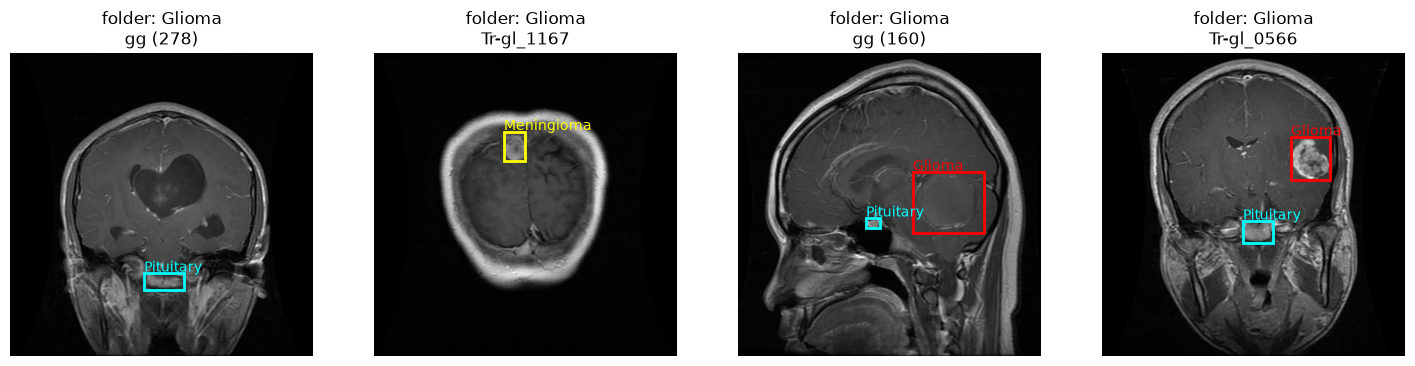

In [5]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

root = "../data"
names = {0: "Glioma", 1: "Meningioma", 2: "No Tumor", 3: "Pituitary"}
colors = {0: "red", 1: "yellow", 2: "white", 3: "cyan"}

def find_image(split, cls, stem):
    d = f"{root}/{split}/{cls}/images"
    for f in os.listdir(d):
        if os.path.splitext(f)[0] == stem:
            return f"{d}/{f}"

def show(ax, split, cls, stem):
    img = Image.open(find_image(split, cls, stem)).convert("RGB")
    W, H = img.size
    ax.imshow(img)
    path = f"{root}/{split}/{cls}/labels/{stem}.txt"
    for line in open(path).read().strip().splitlines():
        c, x, y, w, h = line.split()
        c = int(c); x, y, w, h = map(float, (x, y, w, h))
        ax.add_patch(patches.Rectangle(((x - w/2) * W, (y - h/2) * H), w * W, h * H,
                                       fill=False, edgecolor=colors[c], linewidth=2))
        ax.text((x - w/2) * W, (y - h/2) * H - 3, names[c], color=colors[c])
    ax.set_title(f"folder: {cls}\n{stem}")
    ax.axis("off")

# 2 "wrong only" examples + 2 "mixed" examples from Train/Glioma
mixed = []
for f in os.listdir(f"{root}/Train/Glioma/labels"):
    ids = {l.split()[0] for l in open(f"{root}/Train/Glioma/labels/{f}").read().strip().splitlines()}
    if "0" in ids and len(ids) > 1:
        mixed.append(os.path.splitext(f)[0])
    if len(mixed) == 2:
        break

samples = [("Glioma", "gg (278)"), ("Glioma", "Tr-gl_1167"),
           ("Glioma", mixed[0]), ("Glioma", mixed[1])]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (cls, stem) in zip(axes, samples):
    show(ax, "Train", cls, stem)
plt.show()

In [6]:
import os
import pandas as pd
from PIL import Image

root = "../data"
class_id = {"Glioma": "0", "Meningioma": "1", "No Tumor": "2", "Pituitary": "3"}
rows = []

for split in ["Train", "Val"]:
    for cls, cid in class_id.items():
        img_dir = f"{root}/{split}/{cls}/images"
        lbl_dir = f"{root}/{split}/{cls}/labels"
        lbl_stems = {os.path.splitext(f)[0] for f in os.listdir(lbl_dir)}

        for f in os.listdir(img_dir):
            stem = os.path.splitext(f)[0]
            row = {"split": split, "folder_class": cls, "stem": stem,
                   "image_path": f"{img_dir}/{f}"}

            # image check
            try:
                with Image.open(row["image_path"]) as im:
                    im.verify()
                with Image.open(row["image_path"]) as im:
                    row["width"], row["height"] = im.size
                row["corrupted"] = False
            except Exception:
                row["width"], row["height"], row["corrupted"] = None, None, True

            # label check
            if stem not in lbl_stems:
                row["status"], row["n_boxes"] = "unpaired", 0
            else:
                lines = open(f"{lbl_dir}/{stem}.txt").read().strip().splitlines()
                ids = {l.split()[0] for l in lines}
                row["n_boxes"] = len(lines)
                if not lines:
                    row["status"] = "empty"
                elif cid not in ids:
                    row["status"] = "wrong_only"
                elif len(ids) > 1:
                    row["status"] = "mixed"
                else:
                    row["status"] = "ok"
            rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(f"{root}/inventory.csv", index=False)

print(df["status"].value_counts(), "\n")
print("corrupted:", df["corrupted"].sum(), "\n")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

status
ok            4974
mixed          257
wrong_only      15
unpaired         2
empty            1
Name: count, dtype: int64 

corrupted: 0 

width  height
512    512       4206
225    225        119
630    630         66
442    442         42
236    236         33
256    256         25
201    251         23
       250         22
214    236         18
468    444         15
dtype: int64


In [7]:
import pandas as pd

df = pd.read_csv("../data/inventory.csv")

clean = df[df["status"].isin(["ok", "mixed"]) & (~df["corrupted"])].copy()
clean.to_csv("../data/inventory_clean.csv", index=False)

print("before:", len(df), "| after:", len(clean), "\n")
print(pd.crosstab(clean["folder_class"], clean["split"], margins=True))

print("\nPercent of Train:")
print((clean[clean["split"] == "Train"]["folder_class"]
       .value_counts(normalize=True) * 100).round(1))

before: 5249 | after: 5231 

split         Train  Val   All
folder_class                  
Glioma         1150  135  1285
Meningioma     1438  140  1578
No Tumor        711   98   809
Pituitary      1423  136  1559
All            4722  509  5231

Percent of Train:
folder_class
Meningioma    30.5
Pituitary     30.1
Glioma        24.4
No Tumor      15.1
Name: proportion, dtype: float64


In [8]:
import hashlib
import pandas as pd

clean = pd.read_csv("../data/inventory_clean.csv")

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

clean["hash"] = clean["image_path"].apply(file_hash)

dup = clean[clean.duplicated("hash", keep=False)].sort_values("hash")
print("images that have an exact copy:", len(dup))
print("unique groups of copies:", dup["hash"].nunique(), "\n")

# same hash, but in different splits or different folders?
g = dup.groupby("hash").agg(n=("stem", "count"),
                            splits=("split", lambda s: sorted(set(s))),
                            classes=("folder_class", lambda s: sorted(set(s))))
print(g.head(10))
print("\ncopies across Train and Val:", sum(len(s) > 1 for s in g["splits"]))
print("copies with different classes:", sum(len(c) > 1 for c in g["classes"]))

clean.to_csv("../data/inventory_clean.csv", index=False)

images that have an exact copy: 2554
unique groups of copies: 1223 

                                  n        splits       classes
hash                                                           
0010727efcd278c61306172ec0ca5a3f  2       [Train]   [Pituitary]
0052c398399075925e0fad61910613b0  2       [Train]  [Meningioma]
009a823eceb6ec31b2b3417850c1e6f9  2  [Train, Val]  [Meningioma]
00ff170dab2988e442309f7812c13276  2  [Train, Val]      [Glioma]
017f984430664167e6a6067963c77364  2       [Train]  [Meningioma]
019f8b7d5a0d418509399b63588743cc  2       [Train]   [Pituitary]
01de04449e1175e897fdc09d8917cc29  2  [Train, Val]  [Meningioma]
0239209ee6590fb477087edc0685c560  2       [Train]  [Meningioma]
02416475cb99cda7d3ffeb4cd828a2a6  2       [Train]  [Meningioma]
02901351cdefc7442c9f0b3adf20f3ec  2       [Train]  [Meningioma]

copies across Train and Val: 213
copies with different classes: 0


In [9]:
import pandas as pd

clean = pd.read_csv("../data/inventory_clean.csv")

# Put Val first, so Val copies are the ones we keep
clean["split_order"] = clean["split"].map({"Val": 0, "Train": 1})
clean = clean.sort_values(["split_order", "stem"])

dedup = clean.drop_duplicates(subset="hash", keep="first").drop(columns="split_order")
dedup.to_csv("../data/inventory_dedup.csv", index=False)

print("before:", len(clean), "| after:", len(dedup), "\n")
print(pd.crosstab(dedup["folder_class"], dedup["split"], margins=True))

print("\nPercent of Train:")
print((dedup[dedup["split"] == "Train"]["folder_class"]
       .value_counts(normalize=True) * 100).round(1))

print("\nstill duplicated:", dedup.duplicated("hash").sum())

before: 5231 | after: 3900 

split         Train  Val   All
folder_class                  
Glioma         1052  135  1187
Meningioma      954  134  1088
No Tumor        508   91   599
Pituitary       890  136  1026
All            3404  496  3900

Percent of Train:
folder_class
Glioma        30.9
Meningioma    28.0
Pituitary     26.1
No Tumor      14.9
Name: proportion, dtype: float64

still duplicated: 0


In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/inventory_dedup.csv")

train_all = df[df["split"] == "Train"]
val = df[df["split"] == "Val"]

train, test = train_test_split(
    train_all,
    test_size=0.15,
    stratify=train_all["folder_class"],
    random_state=42,
)

train = train.assign(split="train")
test = test.assign(split="test")
val = val.assign(split="val")

final = pd.concat([train, val, test]).reset_index(drop=True)
final.to_csv("../data/inventory_final.csv", index=False)

print(pd.crosstab(final["folder_class"], final["split"], margins=True))

print("\nPercent per split:")
print(pd.crosstab(final["split"], final["folder_class"], normalize="index").round(3) * 100)

# leakage check: no image in two splits
print("\nhash in more than one split:", (final.groupby("hash")["split"].nunique() > 1).sum())

split         test  train  val   All
folder_class                        
Glioma         158    894  135  1187
Meningioma     143    811  134  1088
No Tumor        76    432   91   599
Pituitary      134    756  136  1026
All            511   2893  496  3900

Percent per split:
folder_class  Glioma  Meningioma  No Tumor  Pituitary
split                                                
test            30.9        28.0      14.9       26.2
train           30.9        28.0      14.9       26.1
val             27.2        27.0      18.3       27.4

hash in more than one split: 0
